# 22. Data overview: the New Glenn explosion at every station

A first look at the explosion at LC-36 on 2026-05-29 (UTC day 149), in physical units:

* **channel status** and the **evidence for the dead stations**. Only the Centaur stations were recording:
  the Gems and SmartSolos had been recovered after Artemis II, and no MSFC (DG) data for day 149 are in the
  archive;
* **infraBSU polarity**, from the first motion of the airwave;
* **record sections** of pressure (>0.5 Hz; infraBSU) and vertical ground velocity (1–30 Hz; Trillium),
  sorted by distance from LC-36 and scaled to each trace's peak (peak at the native rate printed at right;
  display decimated to 100 samples/s). Times are after the origin in `newglenn.yaml` (from
  `24_origin_time.ipynb`); triangles mark the airwave predicted from the weather. Gem overflow intervals
  (`flovopy.ingest.gem_overflow`) would be shaded and blanked, but no Gem recorded this event;
* **spectrograms** of pressure and vertical velocity at the nearest working station, B20 (11.8 km);
* the **B20 Chaparral M25 (HDF) clipping**, found by comparison with the co-located infraBSU (HD1);
* a first **peak pressure vs distance** table.

Correction: `newglenn_config.instrument_correct` (`ksclib.centaur.instrument_correct_centaur`, which falls
back to B14's first post-event response file and adds the Chaparral stage, then flips the
`polarity_reversed` channels).

Output (`cfg.OUT_DIR / "22_data_overview"`): `channel_status.csv`, `dead_station_evidence.png`,
`infrabsu_polarity.csv`, `data_overview.png`, `b20_chaparral_clipping.png`, `b20_chaparral_clip_intervals.csv`,
`peak_pressures.csv`, `peak_pressure_vs_distance.png`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import spectrogram, welch

from ksclib import clipping
from ksclib.pressure import event_reduced_pressures
import newglenn_config as cfg
from ksclib.seedcodes import same_code

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('22_data_overview')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
air = cfg.airwave_speeds()            # weather-based airwave speed and travel time per station
print(cfg.EVENT.name, ORIGIN, cfg.PAD, f'({cfg.EVENT.site_lat:.5f}, {cfg.EVENT.site_lon:.5f})')
print('output:', OUT)

New Glenn explosion 2026-05-29T01:00:02.370000Z LC36 (28.47056, -80.54220)
output: /Users/glennthompson/Library/CloudStorage/Box-Box/thompsong/3_Project_Documents/NASAprojects/201602_Rocket_Seismology/writing/NewGlenn/22_data_overview


## Read and correct

Five minutes before to five minutes after the origin. `stream_clip_intervals` finds Gem 16-bit overflow
intervals (steep shocks are not overflow); it returns nothing here because no Gem recorded.

In [2]:
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
clips = cfg.stream_clip_intervals(raw)
st = cfg.instrument_correct(raw)                       # polarity_reversed channels flipped
st_asrec = cfg.instrument_correct(raw, fix_polarity=False)
print(f'{len(raw)} raw channels from', sorted({tr.stats.station for tr in raw}))
print(f'{len(st)} corrected; Gem overflow intervals: {sum(len(v) for v in clips.values())}')

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


42 raw channels from ['B01', 'B03', 'B05', 'B14', 'B20', 'B24', 'B29']
42 corrected; Gem overflow intervals: 14


## Channel status

A Centaur input with nothing connected records only digitizer noise: about 2 counts rms on the Trillium
inputs and about 14 counts on the infrasound inputs at 500 samples/s. Inputs within 20% of the 24-bit
rail have a Trillium mass at its stop or a clipped sensor. B03's Centaur channels are known to be faulty.

In [3]:
FULL_SCALE = 2 ** 23
rows = []
for tr in raw:
    n = tr.slice(ORIGIN - 250, ORIGIN - 20).data.astype(float)
    s = tr.slice(ORIGIN - 10, ORIGIN + 150).data.astype(float)
    cha = tr.stats.channel
    quiet = n.std() < (5 if cha[1:2] == 'H' else 25)
    railed = max(abs(s.min()), abs(s.max())) > 0.8 * FULL_SCALE
    status = ('no sensor (and faulty Centaur)' if tr.stats.station in cfg.EXCLUDE_STATIONS_CENTAUR and quiet else
              'faulty Centaur' if tr.stats.station in cfg.EXCLUDE_STATIONS_CENTAUR else
              'no sensor' if quiet else 'railed/clipped' if railed else 'ok')
    rows.append(dict(id=tr.id, station=tr.stats.station, channel=cha, fs=tr.stats.sampling_rate,
                     distance_km=stations.distance_km[tr.stats.station], noise_counts=n.std(),
                     mean_counts=n.mean(), min_counts=s.min(), max_counts=s.max(), status=status))
status = pd.DataFrame(rows).sort_values(['distance_km', 'channel']).set_index('id')
status.to_csv(OUT / 'channel_status.csv')
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.max_rows', 60):
    display(status)
OK = set(status.index[status.status == 'ok'])

,station,channel,fs,distance_km,noise_counts,mean_counts,min_counts,max_counts,status
id,,,,,,,,,
1R.B20.00.HD1,B20,HD1,100,11.79,343.6,-1.419e+04,-1.078e+05,2.872e+05,ok
1R.B20.00.HD2,B20,HD2,100,11.79,9.154,-787.3,-976,-701,no sensor
1R.B20.00.HDF,B20,HDF,100,11.79,1.566e+05,-2.044e+04,-9.183e+06,9.398e+06,railed/clipped
1R.B20.00.HH1,B20,HH1,100,11.79,1.264e+04,1.573e+04,-1.056e+04,1.48e+05,ok
1R.B20.00.HH2,B20,HH2,100,11.79,1.292e+04,7523,-2.046e+04,1.503e+05,ok
1R.B20.00.HHZ,B20,HHZ,100,11.79,3.694e+04,7.722e+05,4.358e+05,8.846e+05,ok
1R.B24.00.CD0,B24,CD0,500,15.55,13.18,-1462,-1523,-1368,no sensor
1R.B24.00.CD1,B24,CD1,500,15.55,13.42,747.8,693,874,no sensor
1R.B24.00.CD2,B24,CD2,500,15.55,13.25,419.4,372,516,no sensor


### Evidence for the dead stations

For the paper: B01, B03 and B24 recorded only digitizer noise on all six channels.

* **(a)** Pre-event noise spectra in raw counts. A connected Trillium shows the microseism peak and cultural
  noise, tens to thousands of counts; the dead inputs are flat (white), at the digitizer's own level.
* **(b)** The same in the infrasound band.
* **(c)** Raw counts at B01 around the predicted airwave arrival. A small, airwave-timed excursion appears on
  the dead inputs. With no sensor attached this is most likely pressure or vibration acting on the
  digitizer and cabling, so it is not a measurement of ground motion.

count                         mean              
kind    pressure (?D?) seismic (?H?) pressure (?D?) seismic (?H?)
station                                                          
B01                3.0           3.0           13.7           2.2
B03                3.0           3.0           15.5           2.6
B05                2.0           NaN           14.5           NaN
B20                1.0           NaN            9.2           NaN
B24                3.0           3.0           13.3           2.0
B29                2.0           NaN           14.5           NaN

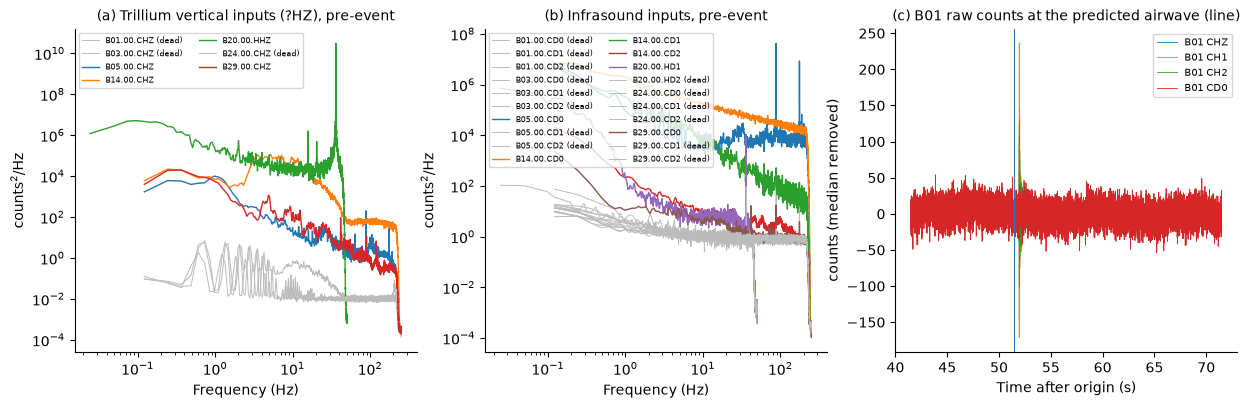

In [4]:
def psd_counts(tr, t0, t1, nperseg=4096):
    x = tr.slice(t0, t1).data.astype(float)
    return welch(x - x.mean(), tr.stats.sampling_rate, nperseg=nperseg)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, cha, title in ((axs[0], 'HZ', '(a) Trillium vertical inputs (?HZ), pre-event'),
                       (axs[1], None, '(b) Infrasound inputs, pre-event')):
    for tr in raw:
        if cha and tr.stats.channel[1:] != cha:
            continue
        if not cha and tr.stats.channel[1:] not in ('D0', 'D1', 'D2'):
            continue
        f, p = psd_counts(tr, ORIGIN - 250, ORIGIN - 20)
        dead = status.loc[tr.id, 'status'].startswith('no sensor')
        ax.loglog(f[1:], p[1:], color='#bbbbbb' if dead else None, lw=0.7 if dead else 1.0,
                  label=tr.id.replace('1R.', '') + (' (dead)' if dead else ''))
    ax.set(xlabel='Frequency (Hz)', ylabel='counts$^2$/Hz', title=title)
    ax.title.set_fontsize(10)
    ax.legend(fontsize=6, ncol=2)
ax = axs[2]
ta = air.travel_time_s['B01']
for cha in ('CHZ', 'CH1', 'CH2', 'CD0'):
    tr = raw.select(station='B01', channel=cha)[0].slice(ORIGIN + ta - 10, ORIGIN + ta + 20)
    y = tr.data.astype(float) - np.median(tr.data)
    ax.plot(tr.times() + ta - 10, y, lw=0.6, label=f'B01 {cha}')
ax.axvline(ta, color='#2a7ab0', lw=0.8)
ax.set(xlabel='Time after origin (s)', ylabel='counts (median removed)',
       title='(c) B01 raw counts at the predicted airwave (line)')
ax.title.set_fontsize(10)
ax.legend(fontsize=7)
fig.savefig(OUT / 'dead_station_evidence.png', dpi=150, bbox_inches='tight')
dead = status[status.status.str.startswith('no sensor')].copy()
dead['kind'] = np.where(dead.channel.str[1] == 'H', 'seismic (?H?)', 'pressure (?D?)')
display(dead.pivot_table(index='station', columns='kind', values='noise_counts', aggfunc=['count', 'mean']).round(1))

## infraBSU polarity

A blast wave starts with a compression. For each working infraBSU, the table gives the sign of the first
excursion above 30% of the peak (0.5–5 Hz) and, at B14, the correlation with B14 CD0, both as recorded,
before the flips listed in `newglenn.yaml` `polarity_reversed`. B14 CD1, B14 CD2 and B05 CD0 start with a
rarefaction. B14 CD1 and CD2 are mirror images of the co-located CD0 (r ≈ −0.99). The likely cause is the
capillary tube mounted on the inner rather than the outer nipple. These channels are sign-flipped from
here on.

In [5]:
ref = st_asrec.select(id='1R.B14.00.CD0')[0].copy().filter('bandpass', freqmin=0.5, freqmax=5)
w = (ORIGIN + air.travel_time_s['B14'] - 5, ORIGIN + air.travel_time_s['B14'] + 12)
pol = []
for tr in st_asrec:
    if tr.id not in OK or not any(same_code(tr.stats.channel, c) for c in cfg.EVENT.infrabsu_channels):
        continue
    t = tr.copy().filter('bandpass', freqmin=0.5, freqmax=5)
    ta = air.travel_time_s[tr.stats.station]
    a = t.slice(ORIGIN + ta - 5, ORIGIN + ta + 10).data
    first = np.sign(a[np.argmax(np.abs(a) > 0.3 * np.abs(a).max())])
    r = np.corrcoef(ref.slice(*w).data, t.slice(*w).data)[0, 1] if tr.stats.station == 'B14' else np.nan
    pol.append(dict(id=tr.id, first_motion='compression' if first > 0 else 'rarefaction', corr_B14_CD0=r,
                    flipped=tr.id in cfg.POLARITY_REVERSED))
pol = pd.DataFrame(pol).set_index('id')
pol.to_csv(OUT / 'infrabsu_polarity.csv')
display(pol.round(2))
assert all((pol.first_motion == 'rarefaction') == pol.flipped), 'polarity_reversed in newglenn.yaml needs updating'

,first_motion,corr_B14_CD0,flipped
id,,,
1R.B05.00.CD0,rarefaction,NaN,True
1R.B14.00.CD0,compression,1.00,False
1R.B14.00.CD1,rarefaction,-0.99,True
1R.B14.00.CD2,rarefaction,-0.99,True
1R.B20.00.HD1,compression,NaN,False
1R.B29.00.CD0,compression,NaN,False


## Record sections and spectrograms

Pressure: the working infraBSU channels (B20 HD1, B14 CD0–CD2, B29 CD0, B05 CD0). Vertical velocity: the
working Trilliums, 1–30 Hz because B20's Trillium has strong tones near 15 and 35 Hz (local machinery).
B20 records at 100 samples/s, the others at 500.

In [6]:
T0, T1 = -10, 90
groups = {'pressure': [], 'velocity': []}
for tr in st:
    if tr.id not in OK:
        continue
    cha = tr.stats.channel
    k = 'pressure' if any(same_code(cha, c) for c in cfg.EVENT.infrabsu_channels) else 'velocity' if cha[1:] == 'HZ' else None
    if not k:
        continue
    t = tr.copy()
    if k == 'pressure':
        t.filter('highpass', freq=0.5, corners=4, zerophase=True)
    else:
        t.filter('bandpass', freqmin=1.0, freqmax=30.0, corners=4, zerophase=True)
    full = t.slice(ORIGIN + T0, ORIGIN + T1)
    m_full = cfg.clip_mask(full, clips.get(tr.id, []))
    peak_full = np.nanmax(np.abs(np.where(m_full, np.nan, full.data.astype(float))))
    if t.stats.sampling_rate > 100:
        t.filter('lowpass', freq=40, corners=8, zerophase=True)
        t.resample(100, no_filter=True)
    t = t.slice(ORIGIN + T0, ORIGIN + T1)
    t.data = np.where(cfg.clip_mask(t, clips.get(tr.id, [])), np.nan, t.data.astype(float))
    groups[k].append((stations.distance_km[tr.stats.station], tr.id, t, peak_full))
for k in groups:
    groups[k].sort(key=lambda x: (x[0], x[1]))
print({k: len(v) for k, v in groups.items()})

{'pressure': 6, 'velocity': 4}


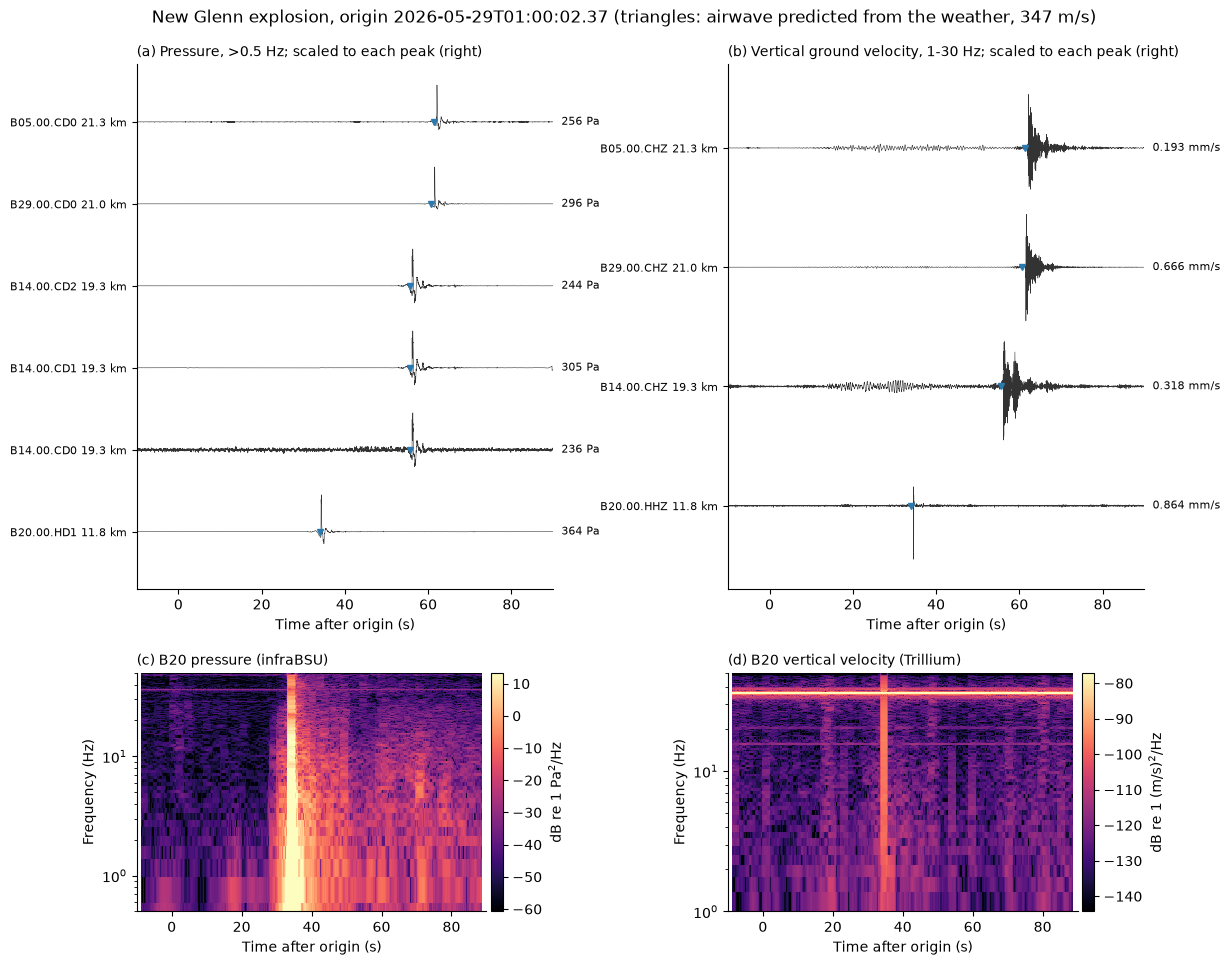

In [7]:
NEAR = 'B20'
fig = plt.figure(figsize=(13, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[2.2, 1], hspace=0.22, wspace=0.42)
for col, (k, scale, fmt) in enumerate((('pressure', 1, '{:.0f} Pa'), ('velocity', 1e3, '{:.3f} mm/s'))):
    ax = fig.add_subplot(gs[0, col])
    for i, (dk, sid, t, peak_full) in enumerate(groups[k]):
        y = t.data * scale
        ax.plot(t.times() + T0, i + 0.45 * y / np.nanmax(np.abs(y)), color='#333333', lw=0.4)
        for a, b in clips.get(sid, []):
            ax.axvspan(a - ORIGIN, b - ORIGIN, ymin=(i + 0.05) / len(groups[k]), ymax=(i + 0.95) / len(groups[k]),
                       color='#eb6834', alpha=0.25, lw=0)
        ax.text(T1 + 2, i, fmt.format(peak_full * scale), va='center', fontsize=8)
        ax.plot(air.travel_time_s[sid.split('.')[1]], i, 'v', color='#2a7ab0', ms=5)
    ax.set_yticks(range(len(groups[k])))
    ax.set_yticklabels([f"{sid.replace('1R.', '')} {dk:.1f} km" for dk, sid, _, _ in groups[k]], fontsize=8)
    ax.set(ylim=(-0.7, len(groups[k]) - 0.3), xlim=(T0, T1), xlabel='Time after origin (s)')
    ax.set_title(('(a) Pressure, >0.5 Hz' if k == 'pressure' else '(b) Vertical ground velocity, 1-30 Hz') +
                 '; scaled to each peak (right)', fontsize=10, loc='left')
for col, (sid, lab, unit, flo) in enumerate(((f'1R.{NEAR}.00.?D1', f'(c) {NEAR} pressure (infraBSU)', 'Pa$^2$/Hz', 0.5),
                                             (f'1R.{NEAR}.00.?HZ', f'(d) {NEAR} vertical velocity (Trillium)', '(m/s)$^2$/Hz', 1.0))):
    tr = st.select(id=sid)[0].copy()
    tr.filter('highpass', freq=flo, corners=4, zerophase=True)
    s = tr.slice(ORIGIN + T0, ORIGIN + T1)
    fs = s.stats.sampling_rate
    f, tt, Sxx = spectrogram(s.data.astype(float), fs, nperseg=256, noverlap=224)
    db = 10 * np.log10(Sxx + 1e-30)
    ax = fig.add_subplot(gs[1, col])
    im = ax.pcolormesh(tt + T0, f, db, shading='auto', cmap='magma',
                       vmin=np.percentile(db, 5), vmax=np.percentile(db, 99.5))
    ax.set(yscale='log', ylim=(flo, fs / 2), xlim=(T0, T1), ylabel='Frequency (Hz)', xlabel='Time after origin (s)')
    ax.set_title(lab, fontsize=10, loc='left')
    fig.colorbar(im, ax=ax, pad=0.01, label=f'dB re 1 {unit}')
c_mean = air.loc[[g[1].split('.')[1] for g in groups['pressure']], 'c_eff_mps'].mean()
fig.suptitle(f'{cfg.EVENT.name}, origin {str(ORIGIN)[:22]} (triangles: airwave predicted from the weather, '
             f'{c_mean:.0f} m/s)', y=0.93)
fig.savefig(OUT / 'data_overview.png', dpi=200, bbox_inches='tight')

## B20 Chaparral M25 (HDF): clipping found against the infraBSU (HD1)

Both sensors are on Centaur Sensor B, which was at 1 Vpp until the 2026-09-23 field visit.

1. **Raw counts.** HDF sits on flat plateaus at the 24-bit rail (±2^23 counts), with brief FIR overshoots
   beyond it: the digitizer clipped (`ksclib.clipping.count_saturation_intervals`).
2. **Comparison with the reference.** The gain between HDF and HD1 is fitted in the late coda (60–120 s,
   1–10 Hz, causal filter so the 360 Pa shock does not ring ahead of itself), where both are small and
   well recorded. HDF is flagged where it departs from the scaled HD1
   by more than 8 times the misfit there (`ksclib.clipping.reference_clip_intervals`).
3. **Recovery.** Comparing the gains fitted in successive coda windows shows how long HDF takes to recover
   after clipping.

The pressure scale of the Chaparral in `newglenn.yaml` (0.4 V/Pa, from the NRL entry used before;
flovopy's station table assumes 0.05 V/Pa) is checked by the same gain.

In [8]:
ddf_raw = raw.select(station='B20', channel='?DF')[0]
band = dict(freqmin=1.0, freqmax=10.0, corners=4, zerophase=False)   # causal: no precursory ringing from the shock
a = st.select(station='B20', channel='?DF')[0].copy().filter('bandpass', **band)
b = st.select(station='B20', channel='?D1')[0].copy().filter('bandpass', **band)
ta = air.travel_time_s['B20']
FIT = (ORIGIN + 60, ORIGIN + 120)
g, lag, r = clipping.fit_reference_gain(a, b, *FIT)
sat = clipping.count_saturation_intervals(ddf_raw.slice(ORIGIN + ta - 5, ORIGIN + ta + 30), frac=0.99, full_scale=FULL_SCALE)
dep = clipping.reference_clip_intervals(a, b, g, FIT, ORIGIN + ta - 5, ORIGIN + ta + 30, lag_s=lag)
iv = pd.DataFrame([dict(method='raw counts at 2^23', start_s=s - ORIGIN, end_s=e - ORIGIN) for s, e in sat] +
                  [dict(method='departs from HD1', start_s=s - ORIGIN, end_s=e - ORIGIN) for s, e in dep])
iv['duration_s'] = iv.end_s - iv.start_s
iv.to_csv(OUT / 'b20_chaparral_clip_intervals.csv', index=False)
print(f'HDF/HD1 gain {g:.4f} (r = {r:.3f}) in 60-120 s; raw HDF range {ddf_raw.data.min():.0f} .. {ddf_raw.data.max():.0f}')
print(iv.groupby('method').agg(n=('start_s', 'size'), first_s=('start_s', 'min'), last_s=('end_s', 'max'),
                               total_s=('duration_s', 'sum')).round(2))
rec = []
for w0 in range(int(ta) + 3, 120, 6):
    gg, _, rr = clipping.fit_reference_gain(a, b, ORIGIN + w0, ORIGIN + w0 + 6)
    rec.append(dict(window_s=f'{w0}-{w0 + 6}', gain=gg, r=rr))
rec = pd.DataFrame(rec)
display(rec.round(3))
v = cfg.centaur.chaparral_config(cfg.EVENT)['V_per_Pa']
peak_dd1 = np.abs(b.slice(ORIGIN + ta - 2, ORIGIN + ta + 5).data).max()
print(f'Relative to the infraBSU, the M25 behaves as {v * g:.3f} V/Pa (configured {v}). '
      f'Clip level about {FULL_SCALE / (v * g * 16e6):.0f} Pa; HD1 peak in this band {peak_dd1:.0f} Pa.')

HDF/HD1 gain 0.0525 (r = 0.899) in 60-120 s; raw HDF range -9182680 .. 9397804
                     n  first_s  last_s  total_s
method                                          
departs from HD1    43    31.13   59.14     8.54
raw counts at 2^23  19    34.25   43.70     3.74


,window_s,gain,r
0,36-42,0.059,0.598
1,42-48,0.252,0.871
2,48-54,0.131,0.715
3,54-60,0.306,0.917
4,60-66,0.050,0.703
5,66-72,0.053,0.973
6,72-78,0.053,0.959
7,78-84,0.053,0.917
8,84-90,0.061,0.937
9,90-96,0.046,0.884


Relative to the infraBSU, the M25 behaves as 0.021 V/Pa (configured 0.4). Clip level about 25 Pa; HD1 peak in this band 224 Pa.


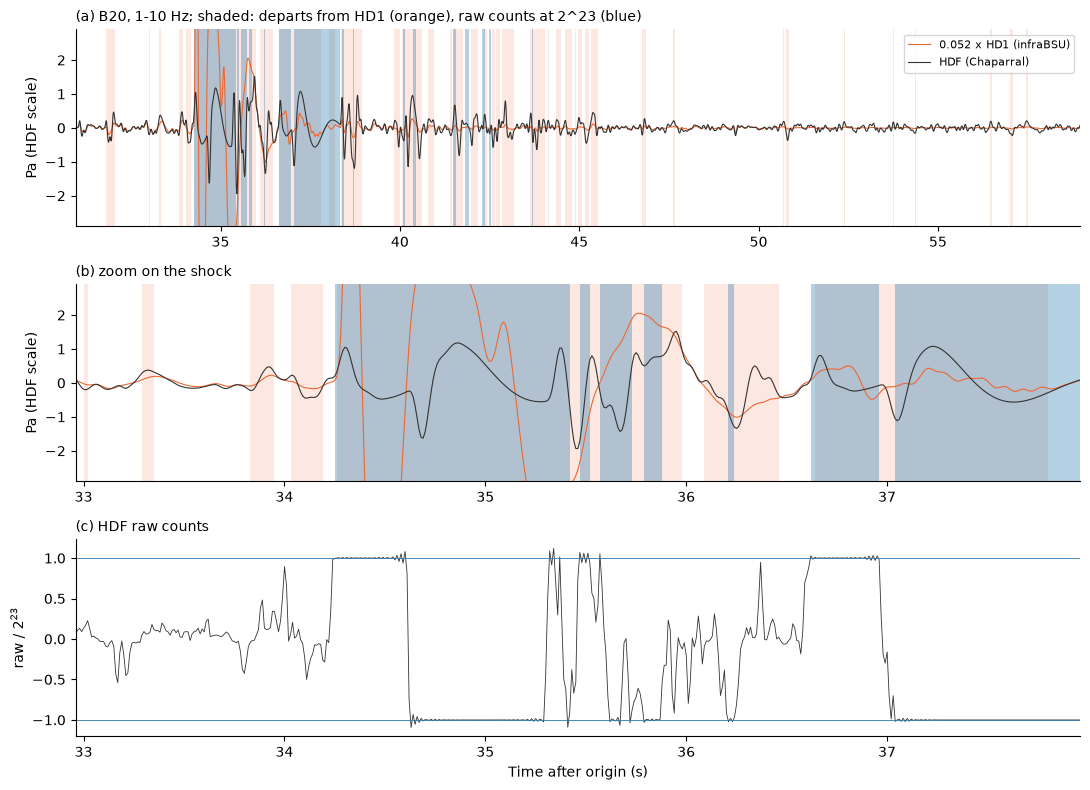

In [9]:
fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, (t0, t1) in zip(axs[:2], ((ta - 3, ta + 25), (ta - 1, ta + 4))):
    sa, sb = a.slice(ORIGIN + t0, ORIGIN + t1), b.slice(ORIGIN + t0, ORIGIN + t1)
    ax.plot(sb.times() + t0, g * sb.data, color='#eb6834', lw=0.8, label=f'{g:.3f} x HD1 (infraBSU)')
    ax.plot(sa.times() + t0, sa.data, color='#333333', lw=0.8, label='HDF (Chaparral)')
    for s, e in dep:
        ax.axvspan(s - ORIGIN, e - ORIGIN, color='#eb6834', alpha=0.15, lw=0)
    for s, e in sat:
        ax.axvspan(s - ORIGIN, e - ORIGIN, color='#2a7ab0', alpha=0.35, lw=0)
    lim = 1.5 * np.abs(sa.data).max()
    ax.set(ylim=(-lim, lim), xlim=(t0, t1), ylabel='Pa (HDF scale)')
axs[0].legend(fontsize=8, loc='upper right')
axs[0].set_title('(a) B20, 1-10 Hz; shaded: departs from HD1 (orange), raw counts at 2^23 (blue)', loc='left', fontsize=10)
axs[1].set_title('(b) zoom on the shock', loc='left', fontsize=10)
rr_ = ddf_raw.slice(ORIGIN + ta - 1, ORIGIN + ta + 4)
axs[2].plot(rr_.times() + ta - 1, rr_.data / FULL_SCALE, color='#333333', lw=0.6)
axs[2].axhline(1, color='#2a7ab0', lw=0.6); axs[2].axhline(-1, color='#2a7ab0', lw=0.6)
axs[2].set(xlim=(ta - 1, ta + 4), ylabel='raw / 2$^{23}$', xlabel='Time after origin (s)')
axs[2].set_title('(c) HDF raw counts', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(OUT / 'b20_chaparral_clipping.png', dpi=150, bbox_inches='tight')

## Peak pressure against distance

Baseline-corrected positive and negative peaks (>0.5 Hz) and pressures reduced to 1 km by spherical
spreading (`ksclib.pressure.event_reduced_pressures`, ported from the AMOS-6 paper). For B14 the three
infraBSUs are averaged in the summary. **Caveat:** the infraBSUs share a nominal sensitivity here; the
Artemis II papers will give the relative calibration errors between sensors (and the tote effects above
about 10 Hz), and these peaks should be revised with them. The B14 triad already shows how large the
sensor-to-sensor spread can be.

,id,distance_m,positive_peak_pa,negative_peak_pa,positive_peak_time_s,positive_reduced_pa
0,1R.B20.00.HD1,11793.38,364.40,-119.27,34.34,4297.52
1,1R.B14.00.CD0,19311.80,235.85,-84.51,56.15,4554.68
2,1R.B14.00.CD1,19311.80,304.82,-105.91,56.15,5886.59
3,1R.B14.00.CD2,19311.80,244.02,-82.22,56.15,4712.37
4,1R.B29.00.CD0,21002.68,296.35,-41.20,61.58,6224.16
5,1R.B05.00.CD0,21303.72,255.37,-59.28,62.12,5440.26


,distance_km,n,positive_peak_pa,spread_pa,negative_peak_pa,positive_reduced_pa
station,,,,,,
B20,11.79,1,364.40,0.00,-119.27,4297.52
B14,19.31,3,261.56,68.97,-90.88,5051.22
B29,21.00,1,296.35,0.00,-41.20,6224.16
B05,21.30,1,255.37,0.00,-59.28,5440.26


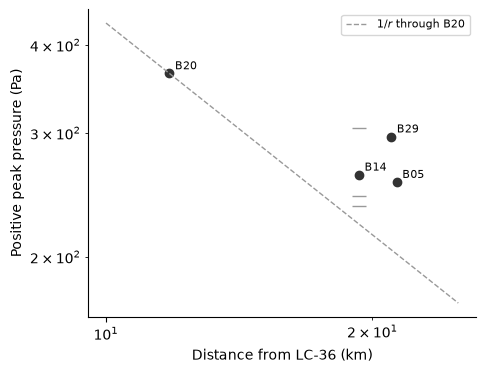

In [10]:
pp = st.copy().select(channel='?D?')
pp = pp.__class__([tr for tr in pp if tr.id in OK and tr.stats.channel != 'HDF'])
pp.filter('highpass', freq=0.5, corners=4, zerophase=True)
peaks = event_reduced_pressures(pp, cfg.EVENT, stations=stations, baseline=(-20, -1), reference_distance_m=1000.0)
peaks.to_csv(OUT / 'peak_pressures.csv', index=False)
cols = ['id', 'distance_m', 'positive_peak_pa', 'negative_peak_pa', 'positive_peak_time_s', 'positive_reduced_pa']
display(peaks[cols].round(2))
summ = peaks.groupby('station').agg(distance_km=('distance_m', lambda x: x.iloc[0] / 1000),
                                    n=('id', 'size'),
                                    positive_peak_pa=('positive_peak_pa', 'mean'),
                                    spread_pa=('positive_peak_pa', lambda x: x.max() - x.min()),
                                    negative_peak_pa=('negative_peak_pa', 'mean'),
                                    positive_reduced_pa=('positive_reduced_pa', 'mean')).sort_values('distance_km')
display(summ.round(2))
fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(summ.distance_km, summ.positive_peak_pa, 'o', color='#333333')
b14 = peaks[peaks.station == 'B14']
ax.loglog(b14.distance_m / 1000, b14.positive_peak_pa, '_', color='#999999', ms=10)
for s_, r in summ.iterrows():
    ax.annotate(s_, (r.distance_km, r.positive_peak_pa), xytext=(4, 3), textcoords='offset points', fontsize=8)
dd = np.linspace(10, 25, 50)
p_ref = summ.positive_peak_pa.iloc[0] * summ.distance_km.iloc[0]
ax.loglog(dd, p_ref / dd, '--', color='#999999', lw=1, label='$1/r$ through B20')
ax.set(xlabel='Distance from LC-36 (km)', ylabel='Positive peak pressure (Pa)')
ax.legend(fontsize=8)
fig.savefig(OUT / 'peak_pressure_vs_distance.png', dpi=150, bbox_inches='tight')

## What the data show (first look)

Written from the run whose outputs are above; re-read if the configuration changes.

* **Recording stations.** Only the Centaur stations recorded. There were no Gems or SmartSolos, and no
  MSFC (DG) data for day 149 are in the archive yet. Working pressure: B20 HD1 (11.8 km), B14 CD0–CD2
  (19.3 km), B29 CD0 (21.0 km), B05 CD0 (21.3 km). Working ground velocity: B20, B14, B29 (three
  components) and B05 (CHZ and CH1; CH2 is at the rail).
* **Dead stations (evidence for the paper).** B01, B03 and B24 recorded only digitizer noise on all six
  channels: about 2 counts rms on the Trillium inputs and 14 on the infrasound inputs, with flat (white)
  spectra and no microseism peak. That is two to five orders of magnitude below the connected inputs (a).
  B20 HD2 and the CD1/CD2 inputs at B05 and B29 are unconnected. On unconnected inputs a small
  airwave-timed excursion (a few hundred counts) appears, most likely pressure or vibration acting on the
  digitizer and cabling (c).
* **Polarity.** B14 CD1, B14 CD2 and B05 CD0 start with a rarefaction (B14 CD1/CD2 correlate at −0.99 with
  the co-located CD0), most likely because the capillary tube is on the inner nipple. They are corrected
  through `polarity_reversed` in `newglenn.yaml`.
* **Amplitudes.** Positive peaks are 364 Pa at B20 (11.8 km) and 236–305 Pa at 19–21 km, well within the
  infraBSU/Centaur range at 1 Vpp (about ±11 kPa). The fall-off is slower than $1/r$: the reduced pressure
  grows from 4.3 kPa·km at B20 to 5–6 kPa·km at 19–21 km. Possible causes are night-time ducting, or B20
  under-reading the shock at 100 samples/s. The infraBSUs share a nominal sensitivity; the relative
  calibration errors from the Artemis II papers should be applied (the B14 triad spreads by 69 Pa,
  about ±13%).
* **Ground motion.** The largest vertical velocities (0.2–0.9 mm/s) come with the airwave. A weak seismic
  wavetrain arrives well before it at every working Trillium; see `26_seismic_arrivals.ipynb`.
* **B20 Chaparral.** HDF clipped at 1 Vpp. Its raw counts sit on plateaus at 2^23 in 19 intervals between the shock
  (34.25 s) and 43.7 s (3.7 s in total). It departs from the co-located infraBSU, by more than 8 times the
  late-coda misfit, in 43 short intervals from 31.1 to 59.1 s (8.5 s in total). The few before the shock
  are HDF's own noise, which is high compared with the quiet coda used for the misfit. The HDF/HD1 gain settles at 0.05
  (r ≈ 0.9–0.98) only after about 60 s, so the M25 takes about 25 s to recover from the overload.
  Relative to the infraBSU it behaves as about 0.021 V/Pa: neither the configured 0.4 V/Pa nor flovopy's
  0.05. Notebook 32 explains why: in normal operation the M25 is 0.4 V/Pa, but between the field visits
  of 4 April and 14 June (which include the explosion) it was faulty and read about 10–20 times low. Its clip level at 1 Vpp is therefore about 25 Pa.